# Customer Retention & Churn Analysis

## Business Problem

Customer churn can significantly affect a company's revenue and long-term growth. Understanding which customers are most likely to leave and the factors associated with churn can help businesses develop more effective retention strategies.

This project analyses customer data from a telecommunications company to identify patterns and characteristics associated with customer churn.

## Project Objectives

- Measure the overall customer churn rate.
- Identify customer segments with higher churn rates.
- Examine how contract type, tenure, pricing, services and payment methods relate to churn.
- Identify potential high-risk customer segments.
- Translate analytical findings into practical customer retention recommendations.

## Tools Used

- Python
- Pandas
- Matplotlib
- Jupyter Notebook
- Power BI
- SQL

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../data/Telco-Customer-Churn.csv')

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

## 1. Data Understanding

Before analysing customer churn, we examine the dataset's structure, data types, missing values and duplicate records to identify potential data quality issues.

#### Check missing values

In [4]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

#### Check duplicate records

In [6]:
df.duplicated().sum()

np.int64(0)

#### Check duplicate customer IDs

In [7]:
df['customerID'].duplicated().sum()

np.int64(0)

In [8]:
df['TotalCharges'].dtype

<StringDtype(storage='python', na_value=nan)>

In [9]:
df['TotalCharges'].isna().sum()

np.int64(0)

In [10]:
df['TotalCharges'].astype(str).str.strip().eq('').sum()

np.int64(11)

In [11]:
blank_charges = df[
    df['TotalCharges'].str.strip().eq('')
]

blank_charges[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


### Data Quality Issue: TotalCharges

Initial inspection identified 11 blank values in the TotalCharges column that were not recognised as missing values.

The column was also stored as a string rather than a numeric data type.

Further investigation was conducted to understand these records before determining the appropriate cleaning approach.

In [12]:
# Replacing blank values with zero
df['TotalCharges'] = df['TotalCharges'].replace(r'^\s*$', '0', regex=True)

# Convingert TotalCharges to a numeric data type
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

In [13]:
df['TotalCharges'].dtype

dtype('float64')

In [14]:
df['TotalCharges'].isna().sum()

np.int64(0)

In [15]:
df.loc[blank_charges.index, ['customerID', 'tenure', 'TotalCharges']]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,0.0
753,3115-CZMZD,0,0.0
936,5709-LVOEQ,0,0.0
1082,4367-NUYAO,0,0.0
1340,1371-DWPAZ,0,0.0
3331,7644-OMVMY,0,0.0
3826,3213-VVOLG,0,0.0
4380,2520-SGTTA,0,0.0
5218,2923-ARZLG,0,0.0
6670,4075-WKNIU,0,0.0


### Data Cleaning Decision

Eleven customer records contained blank values in the TotalCharges column.

Further investigation showed that all 11 customers had a tenure of zero months, suggesting they were newly registered customers with no accumulated charges.

Rather than removing these records, the blank values were replaced with zero, and the TotalCharges column was converted to a numeric data type.

This approach preserved all 7,043 customer records for analysis.

In [16]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate customer IDs:", df['customerID'].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


## 2. Exploratory Data Analysis

### 2.1 Overall Customer Churn

This section examines the proportion of customers who churned compared with those who remained with the company.

In [17]:
# Count customers by churn status
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [18]:
# Calculate churn percentages
df['Churn'].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [19]:
churn_by_contract = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_contract.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


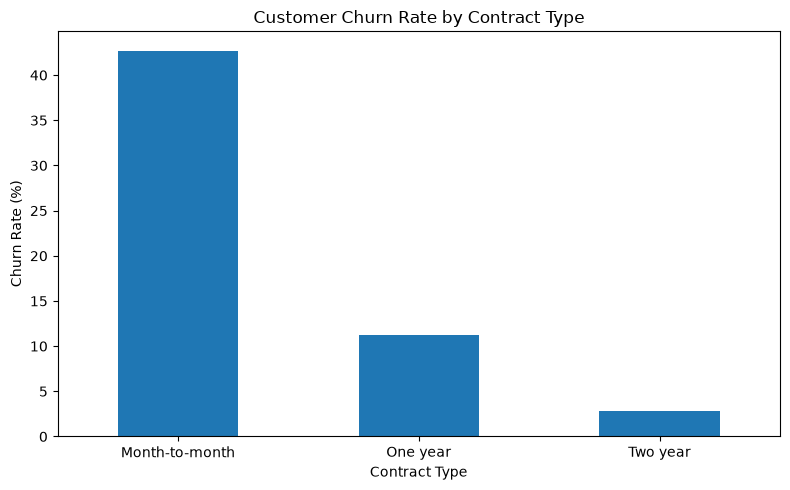

In [20]:
churn_by_contract['Yes'].sort_values(ascending=False).plot(
    kind='bar',
    figsize=(8, 5),
    title='Customer Churn Rate by Contract Type',
    ylabel='Churn Rate (%)',
    xlabel='Contract Type'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Finding: Contract Type

Customer churn varies considerably across contract types.

Month-to-month customers recorded the highest churn rate at approximately 42.7%, compared with 11.3% for one-year contracts and 2.8% for two-year contracts.

This suggests that customers on flexible monthly contracts represent an important segment for further retention analysis.

However, this relationship does not establish that contract type directly causes churn.

In [21]:
df['tenure_group'] = pd.cut(
    df['tenure'],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        '0-6 months',
        '7-12 months',
        '13-24 months',
        '25-48 months',
        '49-72 months'
    ]
)

In [22]:
churn_by_tenure = pd.crosstab(
    df['tenure_group'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_tenure.round(2)

Churn,No,Yes
tenure_group,,
0-6 months,47.06,52.94
7-12 months,64.11,35.89
13-24 months,71.29,28.71
25-48 months,79.61,20.39
49-72 months,90.49,9.51


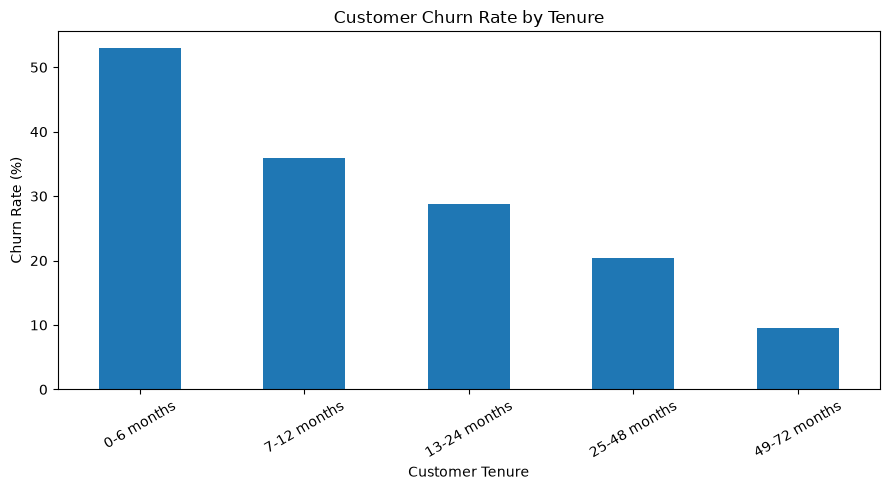

In [23]:
churn_by_tenure['Yes'].plot(
    kind='bar',
    figsize=(9, 5),
    title='Customer Churn Rate by Tenure',
    xlabel='Customer Tenure',
    ylabel='Churn Rate (%)'
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [24]:
churn_contract_tenure = pd.crosstab(
    [df['tenure_group'], df['Contract']],
    df['Churn'],
    normalize='index'
) * 100

churn_contract_tenure['Yes'].round(2)

tenure_group  Contract      
0-6 months    Month-to-month    55.20
              One year          10.26
              Two year           0.00
7-12 months   Month-to-month    42.00
              One year          10.59
              Two year           0.00
13-24 months  Month-to-month    37.72
              One year           8.12
              Two year           0.00
25-48 months  Month-to-month    32.92
              One year          10.62
              Two year           2.19
49-72 months  Month-to-month    26.02
              One year          12.93
              Two year           3.33
Name: Yes, dtype: float64

In [25]:
df.groupby('Churn')['MonthlyCharges'].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [26]:
df.groupby('Churn')['MonthlyCharges'].median()

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64

In [27]:
df.groupby('Churn')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


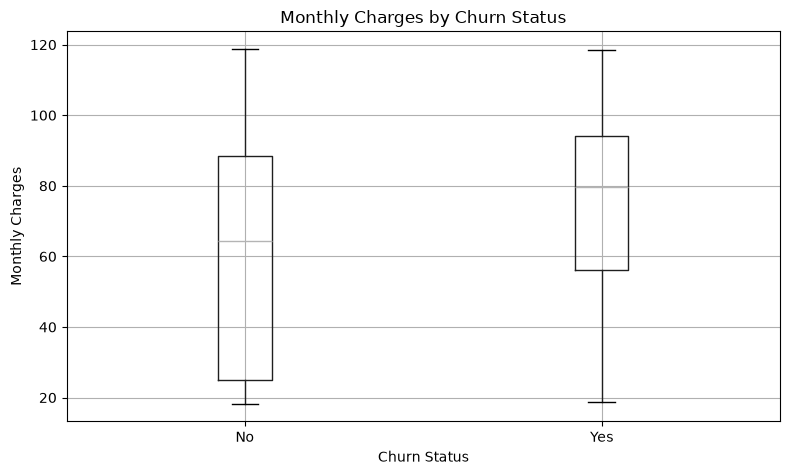

In [28]:
df.boxplot(
    column='MonthlyCharges',
    by='Churn',
    figsize=(8, 5)
)

plt.title('Monthly Charges by Churn Status')
plt.suptitle('')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')
plt.tight_layout()
plt.show()

### Key Finding: Monthly Charges

Customers who churned had higher monthly charges on average (74.44) than customers who remained (61.27), representing a difference of approximately 21.5%.

The median monthly charge was also higher among churned customers (79.65 versus 64.43).

These findings suggest an association between higher monthly charges and customer churn. However, additional analysis is needed to determine whether this relationship persists across different customer segments.

In [29]:
df['charge_group'] = pd.qcut(
    df['MonthlyCharges'],
    q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

In [30]:
churn_by_charges = pd.crosstab(
    df['charge_group'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_charges.round(2)

Churn,No,Yes
charge_group,,
Low,88.76,11.24
Medium-Low,75.42,24.58
Medium-High,62.49,37.51
High,67.12,32.88


In [31]:
df['charge_group'].value_counts().sort_index()

charge_group
Low            1762
Medium-Low     1766
Medium-High    1757
High           1758
Name: count, dtype: int64

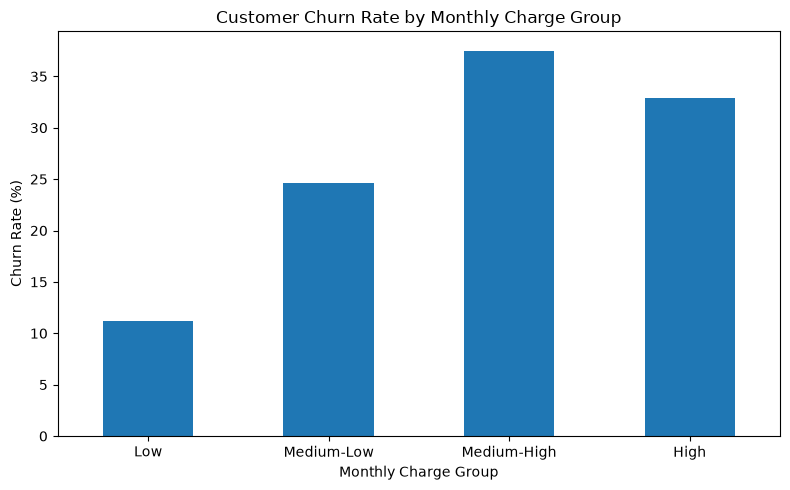

In [32]:
churn_by_charges['Yes'].plot(
    kind='bar',
    figsize=(8, 5),
    title='Customer Churn Rate by Monthly Charge Group',
    xlabel='Monthly Charge Group',
    ylabel='Churn Rate (%)'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Finding: Monthly Charge Segmentation

Customer churn generally increases across higher monthly charge categories, although the relationship is not strictly linear.

The Medium-High charge group recorded the highest churn rate (37.51%), followed by the High group (32.88%). The Low charge group recorded the lowest churn rate (11.24%).

These findings suggest that monthly charges are associated with customer churn, but other factors may influence the relationship.

In [33]:
churn_by_internet = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_internet.round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [34]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [35]:
df.groupby('InternetService')['MonthlyCharges'].mean().round(2)

InternetService
DSL            58.10
Fiber optic    91.50
No             21.08
Name: MonthlyCharges, dtype: float64

In [36]:
pd.crosstab(
    df['InternetService'],
    df['charge_group'],
    normalize='index'
).mul(100).round(2)

charge_group,Low,Medium-Low,Medium-High,High
InternetService,,,,
DSL,9.75,66.29,21.89,2.07
Fiber optic,0.00,5.20,39.63,55.17
No,100.00,0.00,0.00,0.00


In [37]:
churn_service_charges = pd.crosstab(
    [df['InternetService'], df['charge_group']],
    df['Churn'],
    normalize='index'
) * 100

churn_service_charges['Yes'].round(2)

InternetService  charge_group
DSL              Low             36.02
                 Medium-Low      21.12
                 Medium-High      6.42
                 High             2.00
Fiber optic      Medium-Low      59.01
                 Medium-High     50.94
                 High            33.78
No               Low              7.40
Name: Yes, dtype: float64

### Key Finding: Internet Service Type

Fiber-optic customers recorded the highest churn rate (41.89%), compared with DSL customers (18.96%) and customers without internet service (7.40%).

Fiber optic also represents the largest internet service segment, accounting for approximately 44% of customers.

These findings identify fiber-optic customers as an important segment for further retention analysis. Additional investigation is needed to understand how monthly charges and other customer characteristics relate to their higher observed churn rate.

In [38]:
pd.crosstab(
    df['InternetService'],
    df['charge_group']
)

charge_group,Low,Medium-Low,Medium-High,High
InternetService,,,,
DSL,236,1605,530,50
Fiber optic,0,161,1227,1708
No,1526,0,0,0


In [39]:
fiber_customers = df[
    df['InternetService'] == 'Fiber optic'
]

pd.crosstab(
    fiber_customers['charge_group'],
    fiber_customers['Contract'],
    normalize='index'
).mul(100).round(2)

Contract,Month-to-month,One year,Two year
charge_group,,,
Medium-Low,98.76,0.00,1.24
Medium-High,89.57,7.82,2.61
High,50.94,25.94,23.13


### Key Finding: Internet Service and Monthly Charges

Fiber-optic customers recorded the highest average monthly charges (91.50) and the highest overall churn rate (41.89%).

Approximately 94.8% of fiber-optic customers belonged to the Medium-High or High monthly charge groups.

However, within the fiber-optic segment, churn was lower among customers in the High charge group (33.78%) than those in the Medium-High group (50.94%).

This indicates that the relationship between monthly charges and churn is more complex than initially observed. Contract length, customer tenure and other service characteristics may help explain these differences.

In [40]:
fiber_churn_by_contract = pd.crosstab(
    [fiber_customers['charge_group'], fiber_customers['Contract']],
    fiber_customers['Churn'],
    normalize='index'
) * 100

fiber_churn_by_contract['Yes'].round(2)

charge_group  Contract      
Medium-Low    Month-to-month    59.75
              Two year           0.00
Medium-High   Month-to-month    55.78
              One year          11.46
              Two year           3.12
High          Month-to-month    52.18
              One year          20.99
              Two year           7.59
Name: Yes, dtype: float64

In [41]:
fiber_customers.groupby(
    ['charge_group', 'Contract'],
    observed=True
).size()

charge_group  Contract      
Medium-Low    Month-to-month     159
              Two year             2
Medium-High   Month-to-month    1099
              One year            96
              Two year            32
High          Month-to-month     870
              One year           443
              Two year           395
dtype: int64

### Key Finding: Contract Type, Monthly Charges and Churn

Further segmentation revealed that contract type helps explain differences in churn rates among fiber-optic customers.

Among month-to-month fiber-optic customers, churn decreased from 59.75% in the Medium-Low charge group to 52.18% in the High charge group.

This difference of 7.57 percentage points was considerably smaller than the 25.23 percentage-point gap observed before separating customers by contract type.

The findings suggest that contract distribution is an important factor in the observed relationship between monthly charges and churn.

However, the analysis is descriptive and does not establish causation. Other customer characteristics, including tenure and service subscriptions, may also contribute to these differences.

In [42]:
churn_by_payment = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_payment['Yes'].sort_values(ascending=False).round(2)

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Yes, dtype: float64

In [43]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

### Key Finding: Payment Method and Customer Churn

Customers using electronic checks recorded the highest churn rate (45.29%), compared with 19.11% for mailed checks, 16.71% for automatic bank transfers and 15.24% for automatic credit cards.

Electronic check was also the most common payment method, with 2,365 customers.

These findings suggest that payment method is associated with customer churn. However, differences in contract type, tenure and other customer characteristics may contribute to the observed relationship.

In [44]:
churn_by_support = pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_support['Yes'].round(2)

TechSupport
No                     41.64
No internet service     7.40
Yes                    15.17
Name: Yes, dtype: float64

In [45]:
internet_customers = df[
    df['InternetService'] != 'No'
]

pd.crosstab(
    internet_customers['TechSupport'],
    internet_customers['Churn'],
    normalize='index'
).mul(100).round(2)

Churn,No,Yes
TechSupport,,
No,58.36,41.64
Yes,84.83,15.17


In [47]:
internet_customers['TechSupport'].value_counts()

TechSupport
No     3473
Yes    2044
Name: count, dtype: int64

In [48]:
pd.crosstab(
    fiber_customers['TechSupport'],
    fiber_customers['Churn'],
    normalize='index'
).mul(100).round(2)

Churn,No,Yes
TechSupport,,
No,50.63,49.37
Yes,77.37,22.63


In [49]:
fiber_customers['TechSupport'].value_counts()

TechSupport
No     2230
Yes     866
Name: count, dtype: int64

### Key Finding: Technical Support and Customer Churn

Among customers with internet service, those without a technical support subscription recorded a churn rate of 41.64%, compared with 15.17% for customers with technical support.

The same pattern was observed among fiber-optic customers, where churn was 49.37% for customers without technical support and 22.63% for those with technical support.

These findings indicate a strong association between technical support subscription and customer retention.

However, the analysis does not establish a causal relationship. Other factors, such as contract type and customer tenure, may contribute to the observed differences.

**Business implication:** The company could investigate whether customers without technical support face unmet service needs and evaluate targeted retention initiatives for these customers.

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   str     
 1   gender            7043 non-null   str     
 2   SeniorCitizen     7043 non-null   int64   
 3   Partner           7043 non-null   str     
 4   Dependents        7043 non-null   str     
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   str     
 7   MultipleLines     7043 non-null   str     
 8   InternetService   7043 non-null   str     
 9   OnlineSecurity    7043 non-null   str     
 10  OnlineBackup      7043 non-null   str     
 11  DeviceProtection  7043 non-null   str     
 12  TechSupport       7043 non-null   str     
 13  StreamingTV       7043 non-null   str     
 14  StreamingMovies   7043 non-null   str     
 15  Contract          7043 non-null   str     
 16  PaperlessBilling  7043 non-null   s

In [51]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
tenure_group        0
charge_group        0
dtype: int64

## Overall Conclusion and Business Recommendations

This analysis examined customer churn patterns across 7,043 telecom customers, identifying an overall churn rate of **26.54%**.

The findings revealed several customer characteristics associated with higher churn:

- **Contract type:** Month-to-month customers recorded a churn rate of 42.71%, compared with 2.83% for customers on two-year contracts.
- **Customer tenure:** Customers in their first six months had a churn rate of 52.94%, highlighting the importance of early customer engagement.
- **Internet service:** Fiber-optic customers recorded a churn rate of 41.89%, suggesting a need to investigate service experiences and customer expectations.
- **Payment method:** Customers using electronic checks had the highest churn rate at 45.29%.
- **Technical support:** Among customers with internet service, those without technical support recorded a churn rate of 41.64%, compared with 15.17% among those with technical support.

### Business Recommendations

Based on these findings, the company could consider:

1. Strengthening customer onboarding and engagement during the first six months.
2. Exploring incentives that encourage customers to consider longer-term contracts.
3. Investigating potential service issues affecting fiber-optic customers.
4. Reviewing electronic check payment experiences and promoting convenient payment options.
5. Evaluating proactive technical support initiatives for customers who may have unmet service needs.

These recommendations are based on observed relationships within the dataset. Further investigation and controlled testing would be needed to determine whether the proposed actions reduce churn.

### Final Takeaway

The analysis highlights the importance of identifying customer segments with elevated churn rates and using data-driven insights to prioritise retention initiatives. These findings provide a foundation for the customer segmentation and retention dashboard developed in Power BI.

In [53]:
df.to_csv(
    'Telco_Churn_Cleaned.csv',
    index=False
)